In [1]:
## Импортируем все необходимые для работы библиотеки

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
print(pd.__version__)

2.3.3


In [4]:
## Импортируем первый DataFrame customers ,csv были скачаны с https://www.kaggle.com/datasets/saidnizam/messy-e-commerce-dataset

In [5]:
customers = pd.read_csv(
    r"C:\Users\Jane\Desktop\Data for Pandas pet project\customers.csv"
)

In [6]:
## Проверяем ,что колонки выглядят корректно

In [7]:
customers.head(10)

,customer_id,name,age,gender,state,signup_date,email,phone_number,subscribe
0,CUST0001,Gandi,26.0,Male,Sulawesi Utara,2025-05-05,gandi_96@example.com,8422757160,No
1,CUST0002,Cecep,49.0,Male,Aceh,2025-06-02,cecep467@example.com,88171122035,No
2,CUST0003,Artawan,26.0,Male,Jambi,2025-02-11,wahyuninovi@example.net,8692932468,Yes
3,CUST0004,Mulya,61.0,Male,Nusa Tenggara Timur,2025-02-19,nnapitupulu@example.com,8515735210,Yes
4,CUST0005,Taufik,43.0,Male,Kepulauan Riau,2025-08-04,taufik_87@example.com,81034538051,Yes
5,CUST0006,Genta,20.0,Female,Kalimantan Timur,2025-06-04,puyainah@example.com,818757946920,Yes
6,CUST0007,Dimas,18.0,Male,Sumatera Barat,2024-11-14,224dimas@example.com,8189638436,No
7,CUST0008,Nilam,26.0,Female,Jawa Timur,2025-05-22,tariandriani@example.org,8649564474,Yes
8,CUST0009,Emas,29.0,Male,Nusa Tenggara Timur,2023-11-30,emas288@example.com,8712019987,Yes
9,CUST0010,Kani,64.0,Female,Kalimantan Utara,2025-03-05,asmiantosimbolon@example.org,8691418746,Yes


In [8]:
## Проверяем,сколько у нас столбцов и строчек,это может помочь потом,когда будет импортировать второй DataFrame

In [9]:
customers.shape

(1010, 9)

In [10]:
## Проверяем тип колонок(видим,что дата у нас с типом object,лучше сразу перевести в datetime)

In [11]:
customers.dtypes

customer_id      object
name             object
age             float64
gender           object
state            object
signup_date      object
email            object
phone_number      int64
subscribe        object
dtype: object

In [12]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"], errors="coerce")

In [13]:
## Проверяем,если ли у нас незаполненные строчки

In [14]:
customers.isnull().sum()

customer_id      0
name             0
age             56
gender           0
state           54
signup_date      0
email            0
phone_number     0
subscribe        0
dtype: int64

In [15]:
## Проверяем сколько это в % выражении(процент небольшой и строчки не является критичными)

In [16]:
(customers.isnull().sum() / len(customers) * 100).round(2)

customer_id     0.00
name            0.00
age             5.54
gender          0.00
state           5.35
signup_date     0.00
email           0.00
phone_number    0.00
subscribe       0.00
dtype: float64

In [17]:
customers["age"] = customers["age"].fillna(customers["age"].median())
customers["state"] = customers["state"].fillna("Unknown")

In [18]:
customers.isnull().sum()

customer_id     0
name            0
age             0
gender          0
state           0
signup_date     0
email           0
phone_number    0
subscribe       0
dtype: int64

In [19]:
## Проверяем,если ли в таблице дубликаты(видим,что дубликаты идентичны,можем спокойно удалять)

In [20]:
customers.duplicated().sum()

np.int64(10)

In [21]:
customers[customers.duplicated(keep=False)].sort_values(by="customer_id")

,customer_id,name,age,gender,state,signup_date,email,phone_number,subscribe
141,CUST0137,Faizah,58.0,Female,Sulawesi Tenggara,2025-02-15,faizah137@example.com,824030244596,Yes
121,CUST0137,Faizah,58.0,Female,Sulawesi Tenggara,2025-02-15,faizah137@example.com,824030244596,Yes
417,CUST0412,Tira,65.0,Female,Riau,2024-12-22,tira_61@example.com,840843370,No
108,CUST0412,Tira,65.0,Female,Riau,2024-12-22,tira_61@example.com,840843370,No
20,CUST0514,Adinata,60.0,Male,Aceh,2023-12-11,bgunawan@example.net,8287301073,Yes
520,CUST0514,Adinata,60.0,Male,Aceh,2023-12-11,bgunawan@example.net,8287301073,Yes
528,CUST0522,Lurhur,34.0,Male,Papua,2024-08-14,andrianidimas@example.org,8739118659,Yes
104,CUST0522,Lurhur,34.0,Male,Papua,2024-08-14,andrianidimas@example.org,8739118659,Yes
634,CUST0627,Jelita,22.0,Female,Riau,2023-11-30,jelita_54@example.com,8407248064,Yes
703,CUST0627,Jelita,22.0,Female,Riau,2023-11-30,jelita_54@example.com,8407248064,Yes


In [22]:
customers_clean = customers[~customers.duplicated()]

In [23]:
customers_clean.shape

(1000, 9)

In [24]:
## Проверим некоторые колонки ,может где-то значения написаны некорректно

In [25]:
customers_clean["gender"].value_counts()

gender
Female    511
Male      489
Name: count, dtype: int64

In [26]:
customers_clean["state"].value_counts()

state
Unknown                      53
Banten                       36
Papua                        35
Jawa Timur                   35
Sulawesi Utara               33
Kepulauan Bangka Belitung    33
Kepulauan Riau               33
Aceh                         33
Sumatera Utara               33
Nusa Tenggara Barat          32
Sumatera Barat               32
Papua Barat                  31
Kalimantan Timur             31
Sulawesi Tenggara            30
Lampung                      30
Riau                         29
Jawa Tengah                  28
Kalimantan Tengah            28
Gorontalo                    28
DKI Jakarta                  28
Maluku Utara                 27
Bali                         26
DI Yogyakarta                26
Kalimantan Barat             25
Sumatera Selatan             25
Kalimantan Utara             25
Jawa Barat                   24
Bengkulu                     24
Jambi                        24
Sulawesi Selatan             23
Nusa Tenggara Timur          23
Ma

In [27]:
customers_clean["subscribe"].value_counts()

subscribe
Yes    711
No     289
Name: count, dtype: int64

In [28]:
## Импортируем второй DataFrame transactions

In [29]:
transactions = pd.read_csv(
    r"C:\Users\Jane\Desktop\Data for Pandas pet project\transactions.csv"
)

In [30]:
## Проделаем аналогичные шаги,как с первым DataFrame(customers)

In [31]:
transactions.head(10)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,NaN
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,NaN
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,NaN
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,NaN
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,NaN
5,TX_0000005447,CUST0661,2025-09-22,QQ-301,19,321000,Cash,4.0,Completed,NaN
6,TX_0000003024,CUST0370,2025-02-10,GW-908,21,473000,Bank Transfer,40.0,Completed,NaN
7,TX_0000001534,CUST0193,2025-06-19,GF-891,7,329000,Credit Card,12.0,Completed,Very slow shipping
8,TX_0000000264,CUST0033,2025-01-16,ON-125,40,105000,Debit Card,40.0,Completed,NaN
9,TX_0000000744,CUST0093,2024-10-27,EC-962,30,161000,Debit Card,16.0,Completed,NaN


In [32]:
transactions.shape

(8199, 10)

In [33]:
transactions.dtypes

transaction_id         object
customer_id            object
transaction_date       object
product_id             object
quantity                int64
unit_price              int64
payment_method         object
discount_applied      float64
transaction_status     object
review_text            object
dtype: object

In [34]:
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"], errors="coerce"
)

In [35]:
transactions.isnull().sum()

transaction_id           0
customer_id              0
transaction_date         0
product_id               0
quantity                 0
unit_price               0
payment_method           0
discount_applied       426
transaction_status       0
review_text           4916
dtype: int64

In [36]:
transactions["discount_applied"] = transactions["discount_applied"].fillna(0)

In [37]:
transactions.isnull().sum()

transaction_id           0
customer_id              0
transaction_date         0
product_id               0
quantity                 0
unit_price               0
payment_method           0
discount_applied         0
transaction_status       0
review_text           4916
dtype: int64

In [38]:
transactions["review_text"] = transactions["review_text"].fillna("Unknown")

In [39]:
transactions.isnull().sum()

transaction_id        0
customer_id           0
transaction_date      0
product_id            0
quantity              0
unit_price            0
payment_method        0
discount_applied      0
transaction_status    0
review_text           0
dtype: int64

In [40]:
transactions.duplicated().sum()

np.int64(0)

In [41]:
transactions["payment_method"].value_counts()

payment_method
Credit Card      1670
E-wallet         1656
Bank Transfer    1654
Cash             1642
Debit Card       1577
Name: count, dtype: int64

In [42]:
transactions["transaction_status"].value_counts()

transaction_status
Completed    6976
Cancelled     661
Refunded      376
Pending       186
Name: count, dtype: int64

In [43]:
## Очистка данных в двух таблицах проведена,финально проверяем кол-во,customer_id в 2 таблицах и обьединяем

In [44]:
transactions["customer_id"].nunique()

1000

In [45]:
customers["customer_id"].nunique()

1000

In [46]:
merge_tables = transactions.merge(customers_clean, on="customer_id", how="left")

In [47]:
## Проверяем,что после обьединения строчек не стало больше.(ориентируемся на таблицу transactions)

In [48]:
merge_tables.shape

(8199, 18)

In [49]:
merge_tables.head(10)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text,name,age,gender,state,signup_date,email,phone_number,subscribe
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,Unknown,Hendri,42.0,Male,DI Yogyakarta,2024-08-15,margana84@example.net,8303439050,Yes
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,Unknown,Pangeran,58.0,Male,Kepulauan Bangka Belitung,2025-09-20,ranggamaulana@example.net,8556607041,Yes
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,Unknown,Sabrina,21.0,Female,Maluku,2025-09-19,mustikaprasasta@example.com,8779287014,Yes
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,Unknown,Abyasa,50.0,Male,Aceh,2025-04-12,wibisonocaraka@example.com,8436160362,Yes
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,Unknown,Wardaya,58.0,Male,Kalimantan Timur,2024-02-15,wardaya_49@example.com,828349372342,No
5,TX_0000005447,CUST0661,2025-09-22,QQ-301,19,321000,Cash,4.0,Completed,Unknown,Puji,32.0,Female,DI Yogyakarta,2025-09-05,puji_62@example.com,82263520270,Yes
6,TX_0000003024,CUST0370,2025-02-10,GW-908,21,473000,Bank Transfer,40.0,Completed,Unknown,Kiandra,55.0,Female,Unknown,2025-02-07,572kiandra@example.com,8772086268,No
7,TX_0000001534,CUST0193,2025-06-19,GF-891,7,329000,Credit Card,12.0,Completed,Very slow shipping,Kasiyah,45.0,Female,Sulawesi Barat,2025-04-28,537kasiyah@example.com,8096683515,No
8,TX_0000000264,CUST0033,2025-01-16,ON-125,40,105000,Debit Card,40.0,Completed,Unknown,Raden,47.0,Male,Kalimantan Selatan,2023-11-16,raden_6@example.com,8448856016,Yes
9,TX_0000000744,CUST0093,2024-10-27,EC-962,30,161000,Debit Card,16.0,Completed,Unknown,Syahrini,34.0,Female,Unknown,2024-07-14,hariputra@example.com,87412241378,Yes


In [50]:
##Создадим новые колонки год и месяц(сделаем это для поля transaction_date и signup_date,чтобы в дальнейшем можно было корректно строить графики и группировать

In [51]:
merge_tables["transaction_month"] = merge_tables["transaction_date"].dt.month

In [52]:
merge_tables["transaction_year"] = merge_tables["transaction_date"].dt.year

In [53]:
merge_tables["signup_month"] = merge_tables["signup_date"].dt.month

In [54]:
merge_tables["signup_year"] = merge_tables["signup_date"].dt.year

In [55]:
merge_tables.head(10)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text,...,gender,state,signup_date,email,phone_number,subscribe,transaction_month,transaction_year,signup_month,signup_year
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,Unknown,...,Male,DI Yogyakarta,2024-08-15,margana84@example.net,8303439050,Yes,12,2024,8,2024
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,Unknown,...,Male,Kepulauan Bangka Belitung,2025-09-20,ranggamaulana@example.net,8556607041,Yes,9,2025,9,2025
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,Unknown,...,Female,Maluku,2025-09-19,mustikaprasasta@example.com,8779287014,Yes,9,2025,9,2025
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,Unknown,...,Male,Aceh,2025-04-12,wibisonocaraka@example.com,8436160362,Yes,4,2025,4,2025
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,Unknown,...,Male,Kalimantan Timur,2024-02-15,wardaya_49@example.com,828349372342,No,8,2025,2,2024
5,TX_0000005447,CUST0661,2025-09-22,QQ-301,19,321000,Cash,4.0,Completed,Unknown,...,Female,DI Yogyakarta,2025-09-05,puji_62@example.com,82263520270,Yes,9,2025,9,2025
6,TX_0000003024,CUST0370,2025-02-10,GW-908,21,473000,Bank Transfer,40.0,Completed,Unknown,...,Female,Unknown,2025-02-07,572kiandra@example.com,8772086268,No,2,2025,2,2025
7,TX_0000001534,CUST0193,2025-06-19,GF-891,7,329000,Credit Card,12.0,Completed,Very slow shipping,...,Female,Sulawesi Barat,2025-04-28,537kasiyah@example.com,8096683515,No,6,2025,4,2025
8,TX_0000000264,CUST0033,2025-01-16,ON-125,40,105000,Debit Card,40.0,Completed,Unknown,...,Male,Kalimantan Selatan,2023-11-16,raden_6@example.com,8448856016,Yes,1,2025,11,2023
9,TX_0000000744,CUST0093,2024-10-27,EC-962,30,161000,Debit Card,16.0,Completed,Unknown,...,Female,Unknown,2024-07-14,hariputra@example.com,87412241378,Yes,10,2024,7,2024


In [56]:
## Посчитаем выручку по периодам(предварительно проверив ,что означает столбец unit_price)

In [57]:
# Вариант А
merge_tables["revenue_a"] = merge_tables["quantity"] * merge_tables["unit_price"]

# Вариант Б
merge_tables["revenue_b"] = (
    merge_tables["quantity"]
    * merge_tables["unit_price"]
    * (1 - merge_tables["discount_applied"] / 100)
)

# Сравнение
print(merge_tables[["revenue_a", "revenue_b"]].describe())

          revenue_a     revenue_b
count  8.199000e+03  8.199000e+03
mean   6.804829e+06  5.204708e+06
std    5.925992e+06  4.780974e+06
min    7.000000e+02  6.510000e+02
25%    3.050500e+06  2.233700e+06
50%    5.796000e+06  4.255680e+06
75%    9.240000e+06  7.081010e+06
max    7.593300e+07  6.504384e+07


In [58]:
## Видим,что выручка с учетом скидки меньше чем без,наша теория +- подтверждается unit_price это цена за штуку

In [59]:
merge_tables.head(10)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text,...,signup_date,email,phone_number,subscribe,transaction_month,transaction_year,signup_month,signup_year,revenue_a,revenue_b
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,Unknown,...,2024-08-15,margana84@example.net,8303439050,Yes,12,2024,8,2024,13440000,12633600.0
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,Unknown,...,2025-09-20,ranggamaulana@example.net,8556607041,Yes,9,2025,9,2025,10106000,9398580.0
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,Unknown,...,2025-09-19,mustikaprasasta@example.com,8779287014,Yes,9,2025,9,2025,7172000,6598240.0
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,Unknown,...,2025-04-12,wibisonocaraka@example.com,8436160362,Yes,4,2025,4,2025,15884000,9212720.0
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,Unknown,...,2024-02-15,wardaya_49@example.com,828349372342,No,8,2025,2,2024,45000,32850.0
5,TX_0000005447,CUST0661,2025-09-22,QQ-301,19,321000,Cash,4.0,Completed,Unknown,...,2025-09-05,puji_62@example.com,82263520270,Yes,9,2025,9,2025,6099000,5855040.0
6,TX_0000003024,CUST0370,2025-02-10,GW-908,21,473000,Bank Transfer,40.0,Completed,Unknown,...,2025-02-07,572kiandra@example.com,8772086268,No,2,2025,2,2025,9933000,5959800.0
7,TX_0000001534,CUST0193,2025-06-19,GF-891,7,329000,Credit Card,12.0,Completed,Very slow shipping,...,2025-04-28,537kasiyah@example.com,8096683515,No,6,2025,4,2025,2303000,2026640.0
8,TX_0000000264,CUST0033,2025-01-16,ON-125,40,105000,Debit Card,40.0,Completed,Unknown,...,2023-11-16,raden_6@example.com,8448856016,Yes,1,2025,11,2023,4200000,2520000.0
9,TX_0000000744,CUST0093,2024-10-27,EC-962,30,161000,Debit Card,16.0,Completed,Unknown,...,2024-07-14,hariputra@example.com,87412241378,Yes,10,2024,7,2024,4830000,4057200.0


In [60]:
merge_tables[["transaction_year", "transaction_month"]].dtypes

transaction_year     int32
transaction_month    int32
dtype: object

In [61]:
completed = merge_tables[merge_tables["transaction_status"] == "Completed"]

revenue_by_period = (
    completed.groupby(["transaction_year", "transaction_month"], as_index=False)[
        "revenue_b"
    ]
    .sum()
    .sort_values(by=["transaction_year", "transaction_month"])
    .reset_index(drop=True)
)

In [62]:
revenue_by_period

,transaction_year,transaction_month,revenue_b
0,2023,10,1.327980e+07
1,2023,11,8.836050e+06
2,2023,12,1.085811e+08
3,2024,1,2.790720e+07
4,2024,2,5.270418e+07
5,2024,3,9.560153e+07
6,2024,4,1.001248e+08
7,2024,5,1.762608e+08
8,2024,6,1.712085e+08
9,2024,7,2.576168e+08


In [63]:
## Построим график для лучшей визуализации

In [64]:
revenue_by_period["period"] = (
    revenue_by_period["transaction_year"].astype(str)
    + "-"
    + revenue_by_period["transaction_month"].astype(str).str.zfill(2)
)

Text(0, 0.5, 'Выручка')

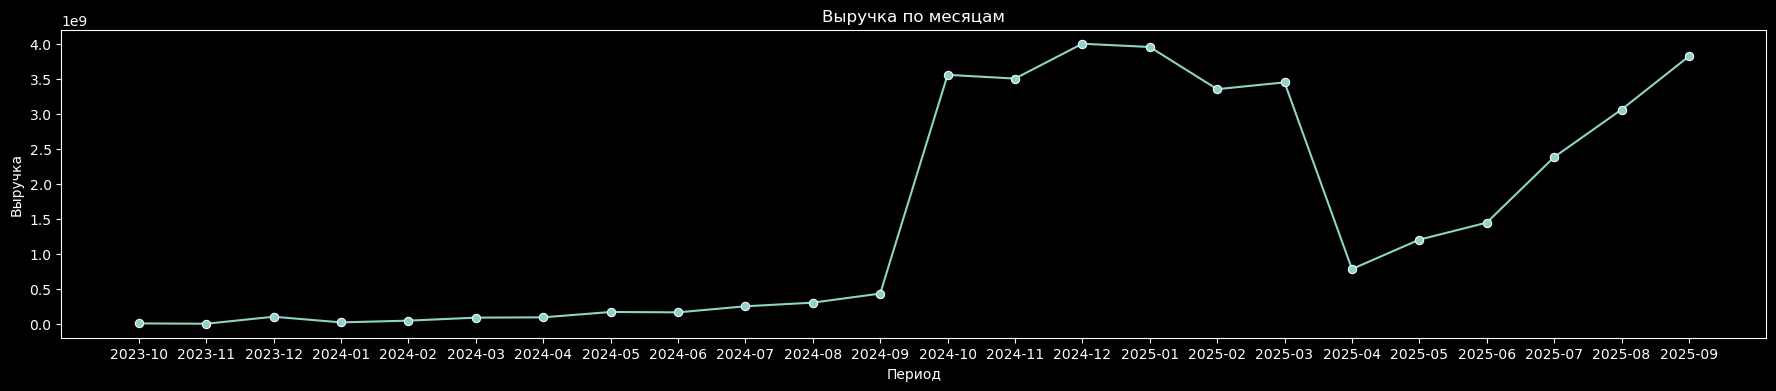

In [65]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(data=revenue_by_period, x="period", y="revenue_b", hue=None, marker="o")
plt.title("Выручка по месяцам")
plt.xlabel("Период")
plt.ylabel("Выручка")

In [66]:
## На основании данных нельзя однозначно сделать выводы,у нас неполные данные за 2023 год,и за 2025 год,но видим,что выручка резко увеличилась на периоде с сент.24 по март.25,потом было падение в апр.25 ,и линейный рост

In [67]:
##Посмотрим распределение выручки по payment_method(берем только со статусом completed)

In [68]:
completed = merge_tables[merge_tables["transaction_status"] == "Completed"]
revenue_payment_method = (
    completed.groupby("payment_method", as_index=False)["revenue_b"]
    .sum()
    .reset_index(drop=True)
)
revenue_payment_method["share_percent"] = (
    revenue_payment_method["revenue_b"]
    / revenue_payment_method["revenue_b"].sum()
    * 100
).round(2)

In [69]:
revenue_payment_method

,payment_method,revenue_b,share_percent
0,Bank Transfer,7.736742e+09,21.30
1,Cash,7.062858e+09,19.44
2,Credit Card,7.527070e+09,20.72
3,Debit Card,6.808494e+09,18.74
4,E-wallet,7.189839e+09,19.79


In [70]:
## в целом сильно больших различий в методе оплатымы не наблюдаем(разница в процентов)

In [71]:
## Посмотрим ,есть ли разница по гендерному признаку

In [72]:
completed = merge_tables[merge_tables["transaction_status"] == "Completed"]
revenue_by_gender = (
    completed.groupby("gender", as_index=False)["revenue_b"]
    .sum()
    .reset_index(drop=True)
)
revenue_by_gender["share_percent"] = (
    revenue_by_gender["revenue_b"] / revenue_by_gender["revenue_b"].sum() * 100
).round(2)

In [73]:
revenue_by_gender

,gender,revenue_b,share_percent
0,Female,1.904325e+10,52.42
1,Male,1.728175e+10,47.58


In [74]:
## Наблюдаем небольшую разницу,видим,что женщины делают покупки чаще,чем мужчины,разница составляет около 5%

In [75]:
## Посмотрим кол_во регистраций по месяцам

In [76]:
registration_counts = (
    merge_tables.drop_duplicates(subset="customer_id")
    .groupby(["signup_year", "signup_month"], as_index=False)["signup_date"]
    .size()
)

In [77]:
registration_counts

,signup_year,signup_month,size
0,2023,9,13
1,2023,10,31
2,2023,11,43
3,2023,12,41
4,2024,1,30
5,2024,2,40
6,2024,3,36
7,2024,4,56
8,2024,5,49
9,2024,6,48


In [78]:
registration_counts["period"] = (
    registration_counts["signup_year"].astype(str)
    + "-"
    + registration_counts["signup_month"].astype(str).str.zfill(2)
)

<Axes: xlabel='period', ylabel='size'>

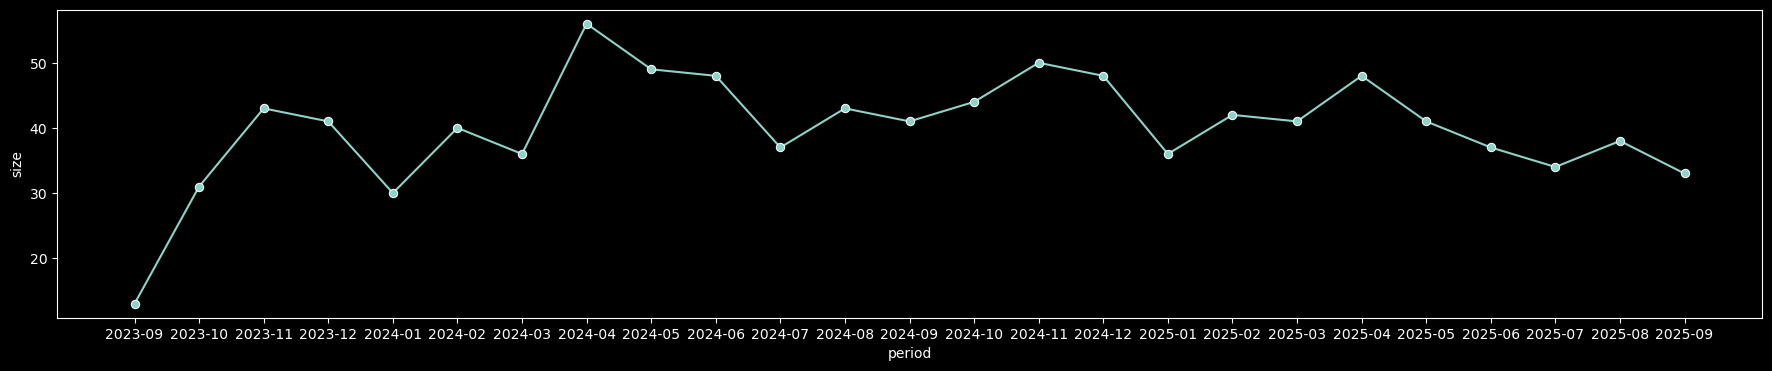

In [79]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(data=registration_counts, x="period", y="size", hue=None, marker="o")

Text(0, 0.5, 'Выручка')

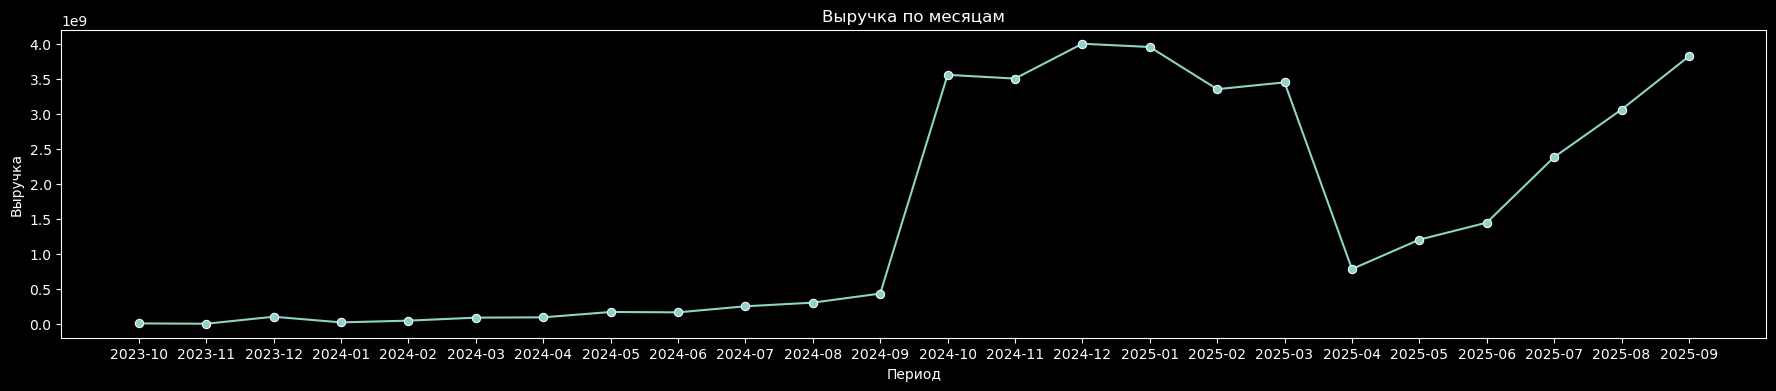

In [80]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(data=revenue_by_period, x="period", y="revenue_b", hue=None, marker="o")
plt.title("Выручка по месяцам")
plt.xlabel("Период")
plt.ylabel("Выручка")

In [81]:
## Проанализиров кол-во регистраций мы не можем сделать одназначного вывода(с пиками в выручке),исходя из графиков,зависимости мы не видим

In [82]:
## Посмотрим на комментарии к заказам

In [83]:
(
    merge_tables["review_text"].value_counts()
    / merge_tables["review_text"].value_counts().sum()
) * 100

review_text
Unknown                                  59.958532
Honest seller, item as described          0.975729
Quality below expectations                0.683010
Amazing product, exceeds expectations     0.658617
Bit disappointing from the photo          0.646420
                                           ...    
Won't buy here again                      0.390291
Friendly seller, item as ordered          0.365898
Size doesn't match expectations           0.365898
High quality product, recommended         0.341505
Product doesn't match picture             0.329308
Name: count, Length: 82, dtype: float64

In [84]:
## Исходя из данных ,мы видим,что 60% покупателей в целом не привыкли оставлять отзывы ,из тех кто оставляет наиболее популярный(около 1%) ,что "Продавец честный,товар ,как в описании"

In [85]:
merge_tables.columns

Index(['transaction_id', 'customer_id', 'transaction_date', 'product_id',
       'quantity', 'unit_price', 'payment_method', 'discount_applied',
       'transaction_status', 'review_text', 'name', 'age', 'gender', 'state',
       'signup_date', 'email', 'phone_number', 'subscribe',
       'transaction_month', 'transaction_year', 'signup_month', 'signup_year',
       'revenue_a', 'revenue_b'],
      dtype='object')

In [86]:
##Посмотрим на проценту подписки

In [87]:
customers_unique = merge_tables.drop_duplicates(subset="customer_id")

subscribe_share = (
    customers_unique["subscribe"].value_counts(normalize=True) * 100
).round(2)

subscribe_share

subscribe
Yes    71.1
No     28.9
Name: proportion, dtype: float64

In [88]:
## Исходя из данных,71% делают подписку(Проверим есть ли различия между мужчинами и женщинами)

In [89]:
subscribe_by_gender = (
    customers_unique.groupby(["gender", "subscribe"]).size().unstack(fill_value=0)
)

subscribe_by_gender["total"] = subscribe_by_gender.sum(axis=1)
subscribe_by_gender["yes_percent"] = (
    subscribe_by_gender["Yes"] / subscribe_by_gender["total"] * 100
).round(2)

subscribe_by_gender

subscribe,No,Yes,total,yes_percent
gender,,,,
Female,150,361,511,70.65
Male,139,350,489,71.57


In [90]:
## Большой разницы в подписке между мужчинами и женщинами нет

In [91]:
## Посмотрим на долю отмен

In [92]:
(
    merge_tables["transaction_status"].value_counts()
    / merge_tables["transaction_status"].value_counts().sum()
) * 100

transaction_status
Completed    85.083547
Cancelled     8.061959
Refunded      4.585925
Pending       2.268569
Name: count, dtype: float64

In [93]:
## Исходя из данных мы видим,что процент отмен около 8%,также мы видим ,что процент возвратов 4,5(в целом их можно считать вместе)

In [94]:
## Посмотрим как наши клиенты распределяются по возрастному признаку,для этого создадим новую колонку

In [95]:
merge_tables["age_group"] = pd.cut(
    merge_tables["age"],
    bins=[0, 25, 45, 65, 100],
    labels=["young", "medium", "adult", "old"],
)

In [96]:
customers_unique = merge_tables.drop_duplicates(subset="customer_id")

age_group_counts = (
    customers_unique.groupby("age_group", observed=True)["customer_id"]
    .size()
    .reset_index(name="count")
)

In [97]:
age_group_counts

,age_group,count
0,young,165
1,medium,441
2,adult,394


In [98]:
age_group_counts["share"] = age_group_counts["count"] / age_group_counts["count"].sum()

In [99]:
age_group_counts

,age_group,count,share
0,young,165,0.165
1,medium,441,0.441
2,adult,394,0.394


In [100]:
## Видим,что покупки в основном делают клиенты в категориях medium и adult(примерно в одинаковой пропорци 41% и 39% соотвественно)

In [101]:
## Построим гистограмму распределения по возрасту

<Axes: xlabel='age', ylabel='Count'>

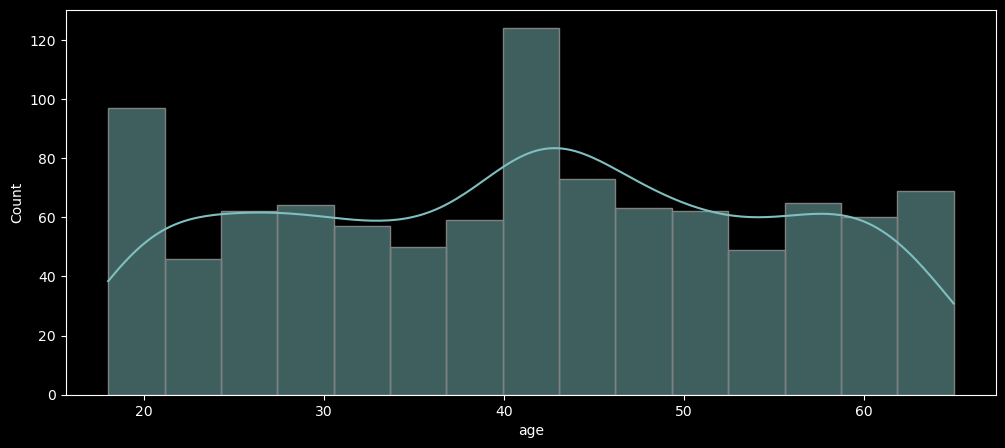

In [102]:
customers_unique = merge_tables.drop_duplicates(subset="customer_id").copy()
customers_unique["age"] = pd.to_numeric(customers_unique["age"], errors="coerce")

plt.style.use("dark_background")
plt.figure(figsize=(12, 5))

sns.histplot(
    data=customers_unique, x="age", bins=15, color="#7fbfbf", edgecolor="gray", kde=True
)

In [103]:
## основной пик — около 40 лет (120+ клиентов);второй пик — около 20 лет (90+ клиентов);«хвост» тянется к 60+

In [104]:
## Посмотрим какой штат дает наибольший процент по выручке и какая у него доля

In [105]:
merge_tables.columns

Index(['transaction_id', 'customer_id', 'transaction_date', 'product_id',
       'quantity', 'unit_price', 'payment_method', 'discount_applied',
       'transaction_status', 'review_text', 'name', 'age', 'gender', 'state',
       'signup_date', 'email', 'phone_number', 'subscribe',
       'transaction_month', 'transaction_year', 'signup_month', 'signup_year',
       'revenue_a', 'revenue_b', 'age_group'],
      dtype='object')

In [106]:
revenue_by_state = (
    merge_tables.groupby("state", as_index=False)["revenue_b"]
    .sum()
    .sort_values(by="revenue_b", ascending=False)
)
revenue_by_state["share"] = (
    revenue_by_state["revenue_b"] / revenue_by_state["revenue_b"].sum()
) * 100

In [107]:
revenue_by_state

,state,revenue_b,share
34,Unknown,2.387158e+09,5.594019
2,Banten,1.880902e+09,4.407668
21,Nusa Tenggara Barat,1.679535e+09,3.935788
30,Sulawesi Utara,1.567210e+09,3.672570
9,Jawa Tengah,1.530401e+09,3.586311
16,Kepulauan Bangka Belitung,1.506134e+09,3.529443
33,Sumatera Utara,1.478101e+09,3.463753
17,Kepulauan Riau,1.397718e+09,3.275384
10,Jawa Timur,1.383822e+09,3.242822
29,Sulawesi Tenggara,1.333627e+09,3.125194


In [108]:
##Исходя из данных топ 2 места,делят штаты Banten и Nusa Tenggara Barat(4,4% и 3,93% соответсвенно)

In [109]:
## Посмотрим,кто является нашим топовым клиентом.

In [110]:
revenue_by_customer_id = (
    merge_tables.groupby("customer_id", as_index=False)["revenue_b"]
    .sum()
    .sort_values(by="revenue_b", ascending=False)
)
revenue_by_customer_id["share"] = (
    revenue_by_customer_id["revenue_b"] / revenue_by_customer_id["revenue_b"].sum()
) * 100

In [111]:
revenue_by_customer_id

,customer_id,revenue_b,share
859,CUST0860,186453640.0,0.436932
380,CUST0381,151750600.0,0.355609
620,CUST0621,145400670.0,0.340729
800,CUST0801,143166580.0,0.335494
737,CUST0738,141506320.0,0.331603
...,...,...,...
250,CUST0251,614400.0,0.001440
288,CUST0289,470920.0,0.001104
245,CUST0246,148000.0,0.000347
0,CUST0001,144000.0,0.000337


In [112]:
## Исходя из данных мы видим,что сильной болльшой разницы нет,все клиенты делятся на менее 1% в доле(в топе CUST0860)

In [113]:
## Посмотрим какой продукт находится в топе продаж и его долю

In [114]:
revenue_by_product_id = (
    merge_tables.groupby("product_id", as_index=False)["revenue_b"]
    .sum()
    .sort_values(by="revenue_b", ascending=False)
)
revenue_by_product_id["share"] = (
    revenue_by_product_id["revenue_b"] / revenue_by_product_id["revenue_b"].sum()
) * 100

In [115]:
revenue_by_product_id

,product_id,revenue_b,share
3058,JT-184,65043840.0,0.152422
5553,RR-116,61891200.0,0.145035
856,CQ-411,61864000.0,0.144971
2916,JF-725,55475200.0,0.129999
5300,QX-469,53565900.0,0.125525
...,...,...,...
5983,TD-348,1700.0,0.000004
3878,MI-208,924.0,0.000002
7898,ZH-692,884.0,0.000002
3337,KP-333,660.0,0.000002


In [116]:
## Ситауция аналогична клиентам,товары делят доли между собой менее 1%(в топе товар с product_id JT-184)

In [117]:
merge_tables.head(5)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text,...,email,phone_number,subscribe,transaction_month,transaction_year,signup_month,signup_year,revenue_a,revenue_b,age_group
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,Unknown,...,margana84@example.net,8303439050,Yes,12,2024,8,2024,13440000,12633600.0,medium
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,Unknown,...,ranggamaulana@example.net,8556607041,Yes,9,2025,9,2025,10106000,9398580.0,adult
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,Unknown,...,mustikaprasasta@example.com,8779287014,Yes,9,2025,9,2025,7172000,6598240.0,young
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,Unknown,...,wibisonocaraka@example.com,8436160362,Yes,4,2025,4,2025,15884000,9212720.0,adult
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,Unknown,...,wardaya_49@example.com,828349372342,No,8,2025,2,2024,45000,32850.0,adult


In [118]:
## Посчитаем кол-во заказов по периодам

In [119]:
order_counts_by_perioud = merge_tables.groupby(
    ["transaction_year", "transaction_month"], as_index=False
)["transaction_id"].count()

In [120]:
order_counts_by_perioud

,transaction_year,transaction_month,transaction_id
0,2023,10,3
1,2023,11,3
2,2023,12,14
3,2024,1,8
4,2024,2,18
5,2024,3,26
6,2024,4,30
7,2024,5,37
8,2024,6,44
9,2024,7,63


In [121]:
order_counts_by_perioud["period"] = (
    order_counts_by_perioud["transaction_year"].astype(str)
    + "-"
    + order_counts_by_perioud["transaction_month"].astype(str).str.zfill(2)
)

<Axes: xlabel='period', ylabel='transaction_id'>

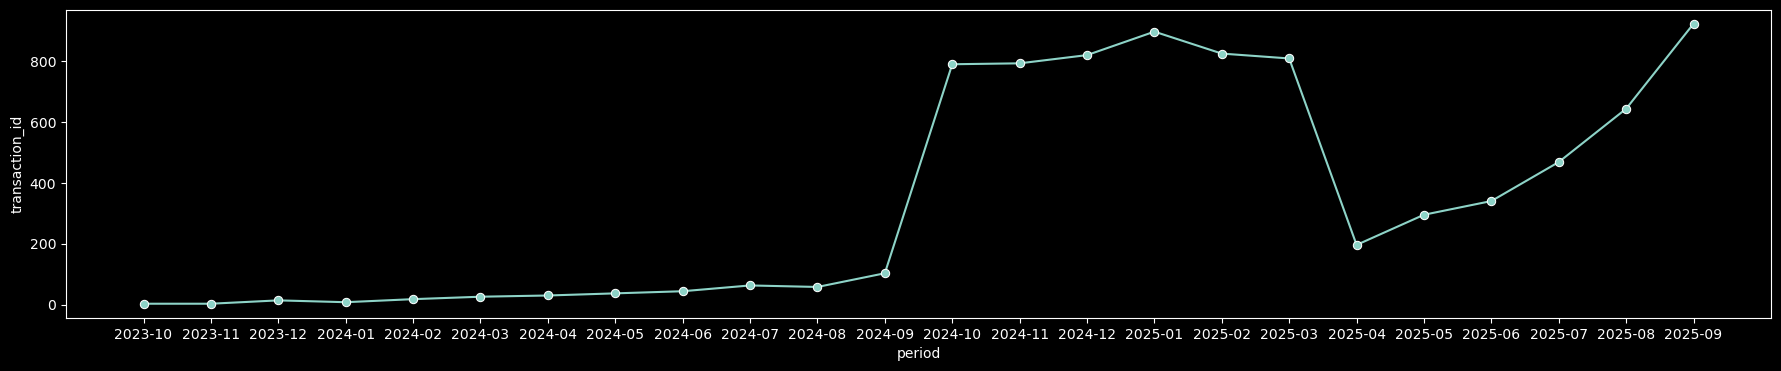

In [122]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(
    data=order_counts_by_perioud, x="period", y="transaction_id", hue=None, marker="o"
)

In [123]:
## На графике мы видим,что выручка у нас выросла из-за увеличения кол-ва заказов,возможно это какой-то новый сайт и у нас было время раскачки

In [124]:
## Посмотрим вырос ли у нас средний чек,по периодам

In [125]:
aov_by_period = merge_tables.groupby(
    ["transaction_year", "transaction_month"], as_index=False
).agg({"transaction_id": "count", "revenue_b": "sum"})
aov_by_period["aov"] = aov_by_period["revenue_b"] / aov_by_period["transaction_id"]

In [126]:
aov_by_period["period"] = (
    aov_by_period["transaction_year"].astype(str)
    + "-"
    + aov_by_period["transaction_month"].astype(str).str.zfill(2)
)

<Axes: xlabel='period', ylabel='aov'>

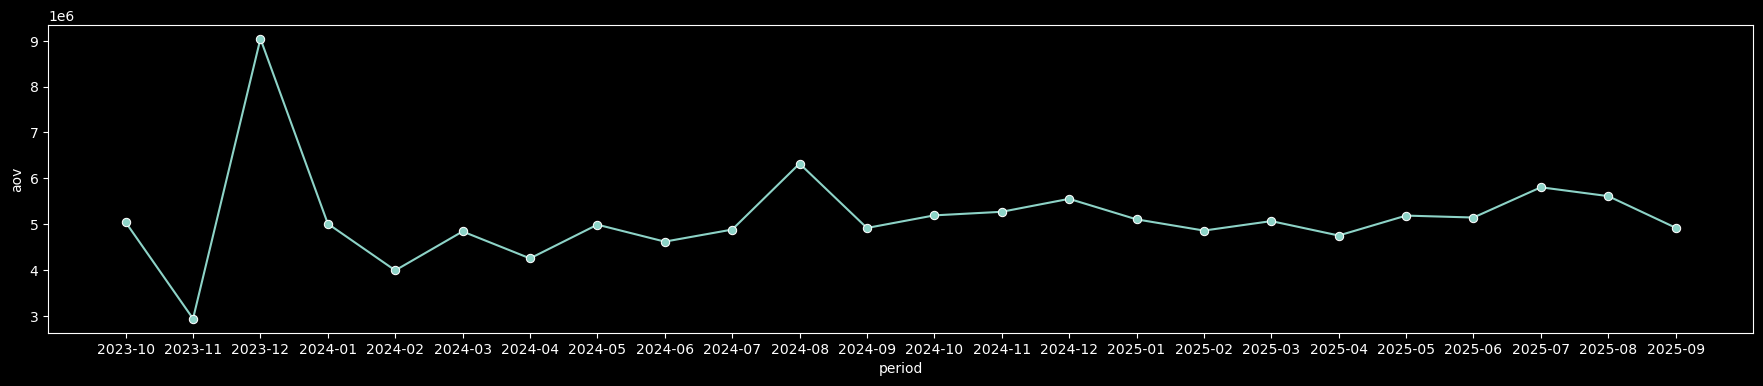

In [127]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(data=aov_by_period, x="period", y="aov", hue=None, marker="o")

In [128]:
## Исходя из данных на графике видим ,что мы был скачок среднего чека на момент открытия магазина,далее был скачок в авг.24,далее более-менее равномерные данные,без сильных выбросов

In [129]:
## Посчитаем средний размер корзины по периодам

In [130]:
avg_items_by_year = (
    completed.groupby(["transaction_year", "transaction_month", "transaction_id"])[
        "quantity"
    ]
    .sum()
    .reset_index()
    .groupby(["transaction_year", "transaction_month"])["quantity"]
    .mean()
    .round(2)
    .reset_index()
)

In [131]:
avg_items_by_year["period"] = (
    avg_items_by_year["transaction_year"].astype(str)
    + "-"
    + avg_items_by_year["transaction_month"].astype(str).str.zfill(2)
)

In [132]:
avg_items_by_year

,transaction_year,transaction_month,quantity,period
0,2023,10,34.50,2023-10
1,2023,11,14.67,2023-11
2,2023,12,30.50,2023-12
3,2024,1,16.43,2024-01
4,2024,2,17.62,2024-02
5,2024,3,21.95,2024-03
6,2024,4,18.42,2024-04
7,2024,5,18.54,2024-05
8,2024,6,21.44,2024-06
9,2024,7,22.21,2024-07


<Axes: xlabel='period', ylabel='quantity'>

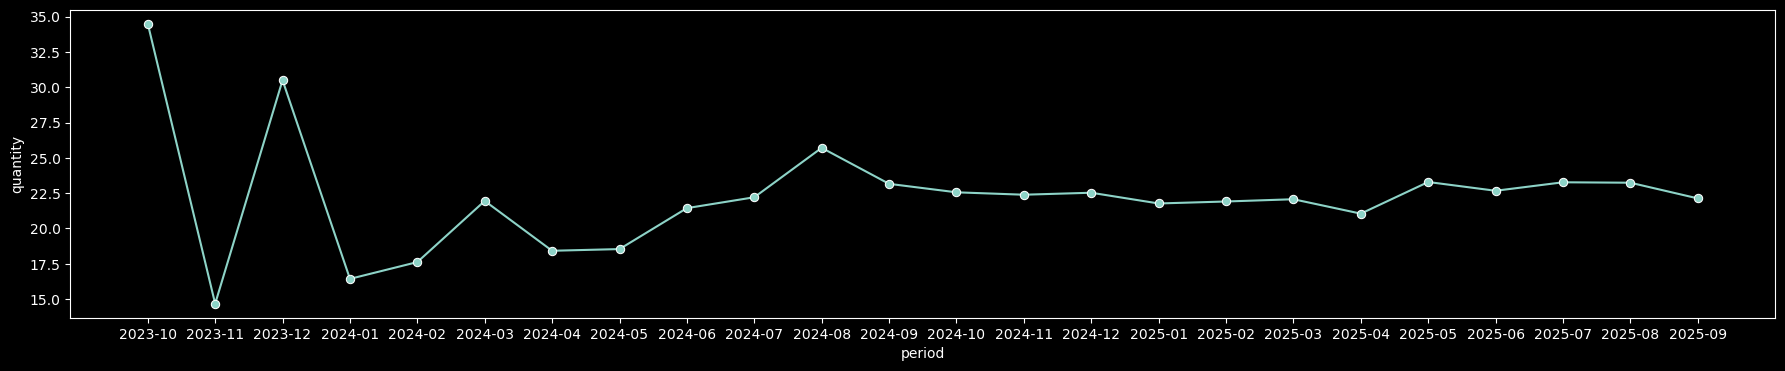

In [133]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(data=avg_items_by_year, x="period", y="quantity", hue=None, marker="o")

In [134]:
## Средний размер покупательской корзины повторяет динамику среднего чека,пики в начале открытия магазина,второй в авг 24,и потом более менее ровно,в среднем где-то 22 товара

In [135]:
merge_tables.head(5)

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text,...,email,phone_number,subscribe,transaction_month,transaction_year,signup_month,signup_year,revenue_a,revenue_b,age_group
0,TX_0000003568,CUST0429,2024-12-29,WZ-802,30,448000,Credit Card,6.0,Completed,Unknown,...,margana84@example.net,8303439050,Yes,12,2024,8,2024,13440000,12633600.0,medium
1,TX_0000001323,CUST0165,2025-09-20,LE-969,31,326000,E-wallet,7.0,Completed,Unknown,...,ranggamaulana@example.net,8556607041,Yes,9,2025,9,2025,10106000,9398580.0,adult
2,TX_0000007976,CUST0969,2025-09-19,CR-562,22,326000,E-wallet,8.0,Completed,Unknown,...,mustikaprasasta@example.com,8779287014,Yes,9,2025,9,2025,7172000,6598240.0,young
3,TX_0000002408,CUST0293,2025-04-23,BL-316,38,418000,Credit Card,42.0,Completed,Unknown,...,wibisonocaraka@example.com,8436160362,Yes,4,2025,4,2025,15884000,9212720.0,adult
4,TX_0000004435,CUST0537,2025-08-28,KL-203,3,15000,E-wallet,27.0,Completed,Unknown,...,wardaya_49@example.com,828349372342,No,8,2025,2,2024,45000,32850.0,adult


In [136]:
## Финально посмотрим на среднюю скидку по периодам

In [137]:
average_discount = (
    merge_tables.groupby(["transaction_year", "transaction_month"])["discount_applied"]
    .mean()
    .reset_index()
)
average_discount

,transaction_year,transaction_month,discount_applied
0,2023,10,38.000000
1,2023,11,17.333333
2,2023,12,25.142857
3,2024,1,10.125000
4,2024,2,24.222222
5,2024,3,19.269231
6,2024,4,19.400000
7,2024,5,24.540541
8,2024,6,24.409091
9,2024,7,25.634921


In [138]:
average_discount["period"] = (
    average_discount["transaction_year"].astype(str)
    + "-"
    + average_discount["transaction_month"].astype(str).str.zfill(2)
)

<Axes: xlabel='period', ylabel='discount_applied'>

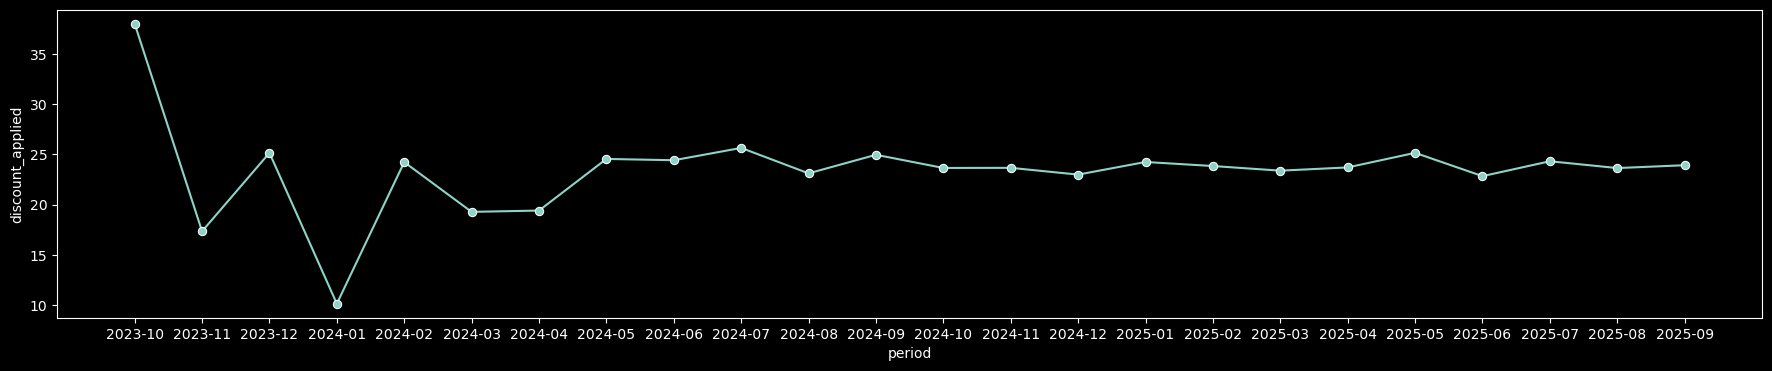

In [139]:
plt.style.use("dark_background")
plt.figure(figsize=(22, 4))
sns.lineplot(
    data=average_discount, x="period", y="discount_applied", hue=None, marker="o"
)

In [140]:
## Средний процент предоставляемой скидки около 24% стабилизировался где-то с мая.24

In [141]:
## Посчитаем RFM сегментацию

In [142]:
snapshot_date = merge_tables["transaction_date"].max() + pd.Timedelta(days=1)
print("Опорная дата:", snapshot_date.date())

rfm = completed.groupby("customer_id", as_index=False).agg(
    recency_days=("transaction_date", lambda x: (snapshot_date - x.max()).days),
    frequency=("transaction_id", "nunique"),
    monetary=("revenue_b", "sum"),
)

rfm.head()

Опорная дата: 2025-09-25


,customer_id,recency_days,frequency,monetary
0,CUST0001,110,1,144000.0
1,CUST0002,51,6,17351320.0
2,CUST0003,101,7,46905430.0
3,CUST0004,23,8,47276950.0
4,CUST0005,2,10,74629620.0


In [143]:
rfm["r_score"] = pd.qcut(rfm["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]
).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.head()

,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score
0,CUST0001,110,1,144000.0,3,1,1
1,CUST0002,51,6,17351320.0,4,2,2
2,CUST0003,101,7,46905430.0,3,3,4
3,CUST0004,23,8,47276950.0,4,3,4
4,CUST0005,2,10,74629620.0,5,4,5


In [144]:
def rfm_segment(row):
    r, f, m = row["r_score"], row["f_score"], row["m_score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "New Customers"
    elif r >= 3 and f <= 2 and m <= 2:
        return "Promising"
    elif r <= 2 and f >= 4 and m >= 4:
        return "At Risk (VIP)"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost"
    elif r == 3 and f <= 2:
        return "Need Attention"
    else:
        return "Others"


rfm["segment"] = rfm.apply(rfm_segment, axis=1)

rfm.head()

,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score,segment
0,CUST0001,110,1,144000.0,3,1,1,Promising
1,CUST0002,51,6,17351320.0,4,2,2,New Customers
2,CUST0003,101,7,46905430.0,3,3,4,Loyal Customers
3,CUST0004,23,8,47276950.0,4,3,4,Loyal Customers
4,CUST0005,2,10,74629620.0,5,4,5,Champions


In [145]:
rfm_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(
        customers=("customer_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_revenue=("monetary", "sum"),
    )
    .sort_values("total_revenue", ascending=False)
)

rfm_summary["customers_share"] = (
    rfm_summary["customers"] / rfm_summary["customers"].sum() * 100
).round(2)

rfm_summary["revenue_share"] = (
    rfm_summary["total_revenue"] / rfm_summary["total_revenue"].sum() * 100
).round(2)

rfm_summary["avg_monetary"] = rfm_summary["avg_monetary"].round(0)
rfm_summary["avg_recency"] = rfm_summary["avg_recency"].round(0)
rfm_summary["avg_frequency"] = rfm_summary["avg_frequency"].round(1)

rfm_summary

,segment,customers,avg_recency,avg_frequency,avg_monetary,total_revenue,customers_share,revenue_share
2,Champions,159,17.0,11.3,68675200.0,1.091936e+10,16.04,30.06
4,Loyal Customers,211,61.0,9.3,49361651.0,1.041531e+10,21.29,28.67
1,At Risk (VIP),61,194.0,10.6,68051660.0,4.151151e+09,6.16,11.43
0,At Risk,103,196.0,7.7,33275173.0,3.427343e+09,10.39,9.44
7,Others,102,115.0,6.9,23792968.0,2.426883e+09,10.29,6.68
6,New Customers,105,21.0,3.5,19309534.0,2.027501e+09,10.60,5.58
3,Lost,190,237.0,2.6,10121615.0,1.923107e+09,19.17,5.29
8,Promising,47,99.0,3.0,12541459.0,5.894486e+08,4.74,1.62
5,Need Attention,13,100.0,4.5,34223472.0,4.449051e+08,1.31,1.22


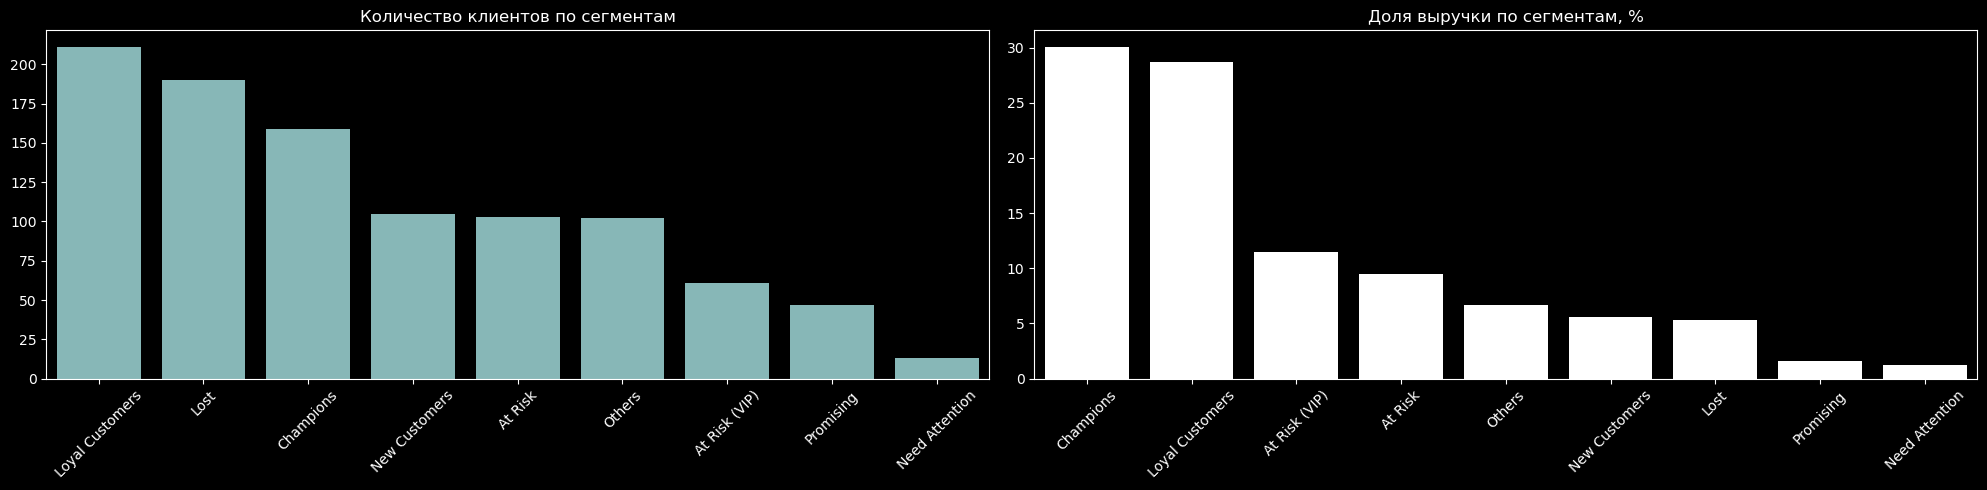

In [146]:
plt.style.use("dark_background")
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

sns.barplot(
    data=rfm_summary.sort_values("customers", ascending=False),
    x="segment",
    y="customers",
    color="#7fbfbf",
    ax=axes[0],
)
axes[0].set_title("Количество клиентов по сегментам", color="white")
axes[0].tick_params(axis="x", rotation=45, colors="white")
axes[0].tick_params(axis="y", colors="white")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

sns.barplot(
    data=rfm_summary.sort_values("revenue_share", ascending=False),
    x="segment",
    y="revenue_share",
    color="white",
    ax=axes[1],
)
axes[1].set_title("Доля выручки по сегментам, %", color="white")
axes[1].tick_params(axis="x", rotation=45, colors="white")
axes[1].tick_params(axis="y", colors="white")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [147]:
summary = """
ИТОГИ АНАЛИЗА
=============

ОЧИСТКА
- 10 дубликатов в customers удалены
- age заполнен медианой, state — 'Unknown'
- discount_applied = 0, review_text = 'Unknown'
- Даты переведены в datetime
- После merge строк не прибавилось: 8 199 = 8 199

ВЫРУЧКА
- 2023 и 2025 неполные — год к году не сравниваю
- Рост с сентября 2024 по март 2025, потом падение в апреле
- Рост идёт за счёт количества заказов, не среднего чека
- Средняя скидка стабилизировалась на 24%

КЛИЕНТЫ
- 71% подписаны на рассылку
- Женщины покупают на 5 п.п. чаще
- Основная аудитория — 25-45 и 45-65 лет
- 8% отмен и 4,5% возвратов

RFM
- Champions и Loyal вместе дают 58% выручки при трети базы
- At Risk (VIP): 60 клиентов = 12% выручки, высокий чек
- New Customers: 10,5% клиентов, но лишь 6% выручки — слабый онбординг
- Lost: 18,5% базы, но 5% выручки — массовая реактивация невыгодна

ЧТО ДОКРУТИТЬ
- Хи-квадрат и t-тест для проверки значимости
- RFM × возраст
- Когортный retention
- Прогноз выручки
"""

print(summary)


ИТОГИ АНАЛИЗА

ОЧИСТКА
- 10 дубликатов в customers удалены
- age заполнен медианой, state — 'Unknown'
- discount_applied = 0, review_text = 'Unknown'
- Даты переведены в datetime
- После merge строк не прибавилось: 8 199 = 8 199

ВЫРУЧКА
- 2023 и 2025 неполные — год к году не сравниваю
- Рост с сентября 2024 по март 2025, потом падение в апреле
- Рост идёт за счёт количества заказов, не среднего чека
- Средняя скидка стабилизировалась на 24%

КЛИЕНТЫ
- 71% подписаны на рассылку
- Женщины покупают на 5 п.п. чаще
- Основная аудитория — 25-45 и 45-65 лет
- 8% отмен и 4,5% возвратов

RFM
- Champions и Loyal вместе дают 58% выручки при трети базы
- At Risk (VIP): 60 клиентов = 12% выручки, высокий чек
- New Customers: 10,5% клиентов, но лишь 6% выручки — слабый онбординг
- Lost: 18,5% базы, но 5% выручки — массовая реактивация невыгодна

ЧТО ДОКРУТИТЬ
- Хи-квадрат и t-тест для проверки значимости
- RFM × возраст
- Когортный retention
- Прогноз выручки

